<h1>Mini-Batch Gradient Descent</h1>

In [278]:
import numpy as np
import matplotlib.pyplot as plt

In [279]:
m = 200

rng = np.random.default_rng(seed=42)

x = 2*rng.random((m, 1))
y = 4 + 3*x + rng.standard_normal((m, 1))

In [280]:
from sklearn.preprocessing import add_dummy_feature

In [281]:
x_b = add_dummy_feature(x)

In [305]:
eta = 0.1
n_epochs = 1000
batch_size = 20

#para despues sacar la grafica costo iteraciones
cost_hist = []

In [306]:
t0, t1 = 5, 50  # hiperparámetros del schedule

def learning_schedule(t):
    return t0 / (t + t1)

In [307]:
theta = rng.standard_normal ((2,1))
theta

array([[-0.18365789],
       [ 0.03004247]])

In [308]:
#comenzamos con valores aleatorios y nos acercamos con cada ciclo a la solucion
for epoch in range (n_epochs):
    #mesclar los indices de los datos usando rng.permutation
    shuffled_indices = rng.permutation(m)

    x_b_shuffled = x_b[shuffled_indices]
    y_shuffled = y[shuffled_indices]

    #creamos los mini-batchs
    for start in range(0, m, batch_size):

        end = start + batch_size

        x_batch = x_b_shuffled[start:end]
        y_batch = y_shuffled[start:end]

        #calculamos error y gradiente para cada grupo
        y_predict = x_batch @ theta
        error = y_predict - y_batch

        gradients = (2 / len(x_batch)) * x_batch.T @ error

        #la actualizacion del tamaño de eta
        n_batches = int(np.ceil(m / batch_size))
        t = epoch * n_batches + i
        eta = learning_schedule(t)

        #actualizamos theta para el siguiente ciclo
        theta = theta - eta * gradients

        #para la grafica costo iteraciones
        y_predict = x_b @ theta
        cost = np.mean((y_predict - y) ** 2)

        cost_hist.append(cost)
theta

array([[3.67278921],
       [3.34518042]])

In [309]:
x_pred = np.array([[0], [2]])
x_pred_b = add_dummy_feature(x_pred)

y_pred = x_pred_b @ theta

<h1>Grafica del historial</h1>

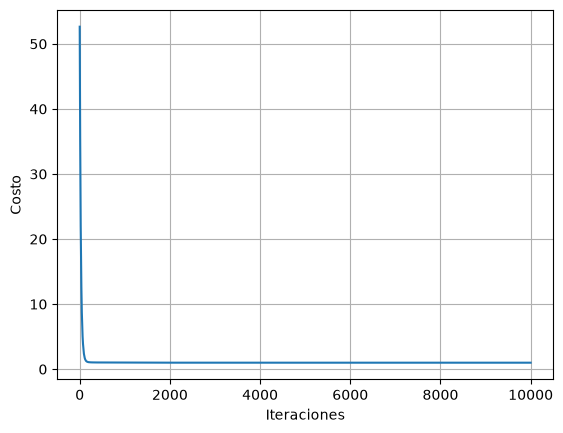

In [310]:
plt.plot(cost_hist)
plt.xlabel("Iteraciones")
plt.ylabel("Costo")
plt.grid(True)
plt.show()

<h1>Grafica</h1>

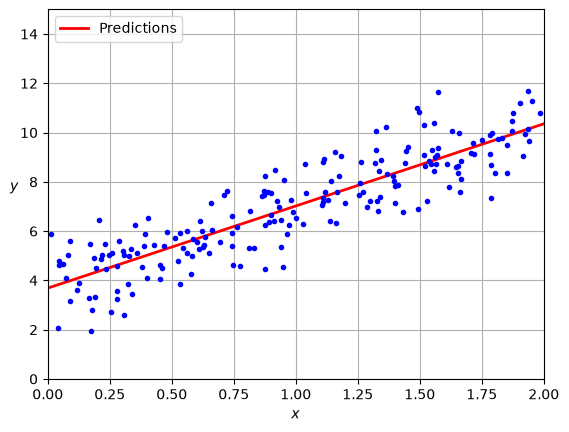

In [288]:
plt.plot (x_pred, y_pred, 'r-', linewidth=2, label= 'Predictions')
plt.plot (x, y, 'b.')

plt.xlabel('$x$')
plt.ylabel('$y$', rotation=0)
plt.legend(loc = 'upper left')
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.show()

<h1>Comparacion con batch graident descent</h1>

In [289]:
eta = 0.1
n_epochs = 1000

In [290]:
rng = np.random.default_rng(seed = 42);

In [291]:
theta_batch = rng.standard_normal ((2,1))

In [292]:
j_log = np.zeros(n_epochs)

for i in range (n_epochs):
    j_log[i] = (1/m)*((x_b@theta_batch-y)**2).sum()

    gradients = (2/m)*x_b.T @ (x_b@theta_batch-y)
    theta_batch = theta_batch - eta * gradients

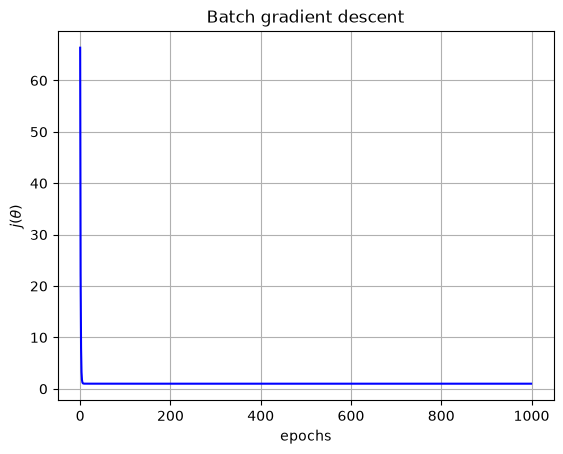

In [293]:
plt.plot(np.arange(n_epochs), j_log, 'b-')
plt.xlabel('epochs')
plt.ylabel(r'$j(\theta)$')
plt.title("Batch gradient descent")
plt.grid(True)
plt.show()

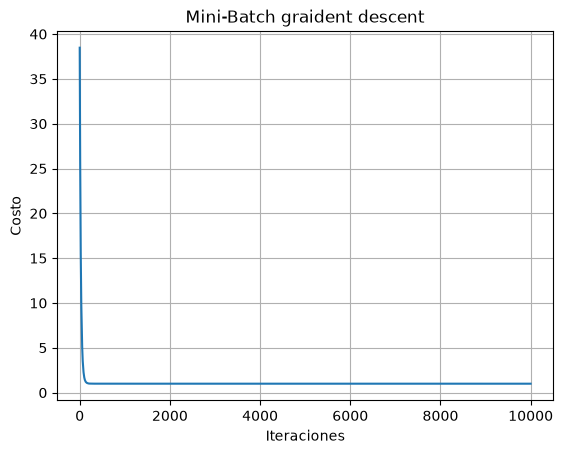

In [294]:
plt.plot(cost_hist)
plt.xlabel("Iteraciones")
plt.ylabel("Costo")
plt.title("Mini-Batch graident descent")
plt.grid(True)
plt.show()

In [295]:
theta_exacta = np.linalg.inv(x_b.T @ x_b) @ x_b.T @ y

In [296]:
print("Parámetros reales del modelo:  θ0 = 4,  θ1 = 3")
print(f"Solución exacta:               θ0 = {theta_exacta[0,0]:.4f},  θ1 = {theta_exacta[1,0]:.4f}")
print(f"Batch Gradient Descent:        θ0 = {theta_batch[0,0]:.4f},  θ1 = {theta_batch[1,0]:.4f}")
print(f"Mini-batch Gradient Descent:   θ0 = {theta[0,0]:.4f},  θ1 = {theta[1,0]:.4f}")

Parámetros reales del modelo:  θ0 = 4,  θ1 = 3
Solución exacta:               θ0 = 3.6908,  θ1 = 3.3296
Batch Gradient Descent:        θ0 = 3.6908,  θ1 = 3.3296
Mini-batch Gradient Descent:   θ0 = 3.6863,  θ1 = 3.3335


Como podemos observar el mini_batch obtuvo θ ≈ [3.75, 3.39]. A comparacion de el gradient descen que es θ ≈ [3.69, 3.32], considerando que los parametros exactos del modelo son [4, 3]. Si tomamos lo anterior en cuenta podemos decir que el mini-batch recupero bien la tendencia de datos, la variacion con los datos exactos se deben a el ruido generado no en si al modelo.